# 03 — First pricing model: constant world and local risk prices

Estimate two nested, joint asset-pricing systems separately for **USD and EUR investors**, using
the same frozen observations and the same three test assets: **World, US, Hungary**.

1. Load and verify the frozen sample.
2. Define the pricing restrictions and a simple multivariate covariance process.
3. Check the likelihood gradients, then fit from several starting points.
4. Inspect convergence and curvature before calculating robust QML uncertainty.
5. Test the local-risk restriction and inspect standardised residuals.

This is an initial benchmark in the paper's GARCH-in-mean family. It uses a **scalar BEKK restriction**,
not the paper's more flexible diagonal specification. Risk prices are constant; there are no currency
pricing terms or economic predictors yet. The EUR cash-proxy limitation from the data notebook remains.

**Environment:** use the existing Miniconda **base** kernel. No new packages or custom kernel are needed.

In [1]:
# Adjustable settings. Never fetch data or change the frozen snapshot in this notebook.
SNAPSHOT = "data/fixed_2026-11-13/from_2000-01"
ANALYSIS_START = None
ANALYSIS_END = None
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70), (0.02, 0.96)]  # alpha, beta
MAX_ITER = 600
TEST_LAGS = 12
REUSE_FITS = True  # False forces re-estimation. Change MODEL_VERSION after model-code edits.
MODEL_VERSION = "scalar_bekk_garch_m_v1"

from pathlib import Path
from io import BytesIO
import hashlib
import importlib.metadata
import json
import os
import platform
import sys

ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import softmax
from scipy.stats import norm, chi2
from packaging.version import Version
sm_version = importlib.metadata.version("statsmodels")
if Version(sm_version) < Version("0.15.0"):
    raise RuntimeError("Run %pip install --upgrade statsmodels==0.15.0, then Restart Kernel and Run All.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != sm_version:
    raise RuntimeError("statsmodels was updated. Restart Kernel and Run All to discard old imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from IPython.display import display, Markdown

versions = {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]}
print("Python:", sys.executable)
print("Packages:", versions)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 40)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
source = ROOT / SNAPSHOT
manifest = json.loads((source / "manifest.json").read_text())
raw = (source / "dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest() != manifest["exports"]["dataset.csv"]:
    raise ValueError("The frozen dataset is not sealed or its checksum differs.")
data = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
data.index = pd.PeriodIndex(data.index, freq="M", name="month")
if not data.index.equals(pd.period_range(data.index[0], data.index[-1], freq="M")):
    raise ValueError("Missing or duplicate months.")
data = data.loc[ANALYSIS_START:ANALYSIS_END].copy()
if len(data) < max(120, 5 * TEST_LAGS) or not 2 <= TEST_LAGS <= 24:
    raise ValueError("Use at least 120 months and TEST_LAGS from 2 to 24 for this initial fit.")
ASSETS = ["World", "US", "Hungary"]
samples = {c: data[[f"rx_{a}_{c.lower()}" for a in ["world", "us", "hu"]]].to_numpy() * 100
           for c in ["USD", "EUR"]}
if not all(np.isfinite(y).all() for y in samples.values()):
    raise ValueError("Non-finite returns.")
scales_by_currency = {c: y.std(axis=0, ddof=1) for c, y in samples.items()}
if not all((s > 0).all() for s in scales_by_currency.values()):
    raise ValueError("A return series is constant.")
OUT = ROOT / "output" / "03_pricing_baseline" / source.parent.name / f"{data.index[0]}_{data.index[-1]}"
OUT.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame({"first": [str(data.index[0])], "last": [str(data.index[-1])],
                      "months": [len(data)], "assets": [", ".join(ASSETS)], "return_unit": ["monthly log %"]}))

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


,first,last,months,assets,return_unit
0,2000-01,2026-09,321,"World, US, Hungary",monthly log %


## 1. Pricing restrictions

All returns below are excess returns in **percentage units**. Let
$H_t=\operatorname{Var}(\varepsilon_t\mid\mathcal F_{t-1})$ and $\varepsilon_t=y_t-\mu_t$.
Asset order is World, US, Hungary. The world-only system imposes $\lambda_{US}=\lambda_{HU}=0$;
the world/local system estimates all three constant prices:

\[
\begin{aligned}
\mu_{W,t}&=\lambda_W H_{WW,t},\\
\mu_{US,t}&=\lambda_W H_{US,W,t}+\lambda_{US}H_{US,US,t},\\
\mu_{HU,t}&=\lambda_W H_{HU,W,t}+\lambda_{HU}H_{HU,HU,t}.
\end{aligned}
\]

There are no free intercepts or AR terms in this initial mean specification. Risk prices may be
positive or negative, avoiding a positivity boundary in the zero-price tests. The US is a test asset,
not an additional common risk factor. The local term uses own conditional variance, as in the supplied
draft's empirical formulation; it is not an orthogonalised residual variance.

Reference: Antell and Vaihekoski, supplied April 2005 draft, equations (8)–(14);
[published paper citation](https://doi.org/10.1016/j.jbankfin.2006.09.013).
The USD/EUR estimations are related views of the same observations, not independent replications.

## 2. A first covariance model

Use the scalar BEKK(1,1) recursion

\[
H_t=(1-\alpha-\beta)\Sigma+\alpha\varepsilon_{t-1}\varepsilon_{t-1}' +\beta H_{t-1},
\qquad H_0=\Sigma.
\]

$\Sigma$ is a positive-definite long-run **innovation** covariance matrix. Its six Cholesky parameters
are estimated jointly, rather than plugging in a sample variance target. Softmax weights ensure
$\alpha>0$, $\beta>0$, and $\alpha+\beta<1$. These weights are shared across the three assets; that is
the main simplification to revisit if residual covariance dynamics remain.

The sample standard deviations below only normalise the Cholesky coordinates for optimisation;
they do not fix the estimated covariance matrix. Risk-price coordinates are scaled by 0.01 internally.
Reported risk prices multiply covariances in squared percentage units; changing return units changes
their numerical values.

In [2]:
PRICE_SCALE = 0.01
TRI = np.tril_indices(3)

def unpack(theta, scales, partial):
    k = 3 if partial else 1
    q = len(theta)
    prices = np.zeros(3)
    prices[:k] = PRICE_SCALE * theta[:k]
    dp = np.zeros((q, 3))
    dp[np.arange(k), np.arange(k)] = PRICE_SCALE
    L = np.zeros((3, 3))
    dL = np.zeros((q, 3, 3))
    for offset, (i, j) in enumerate(zip(*TRI)):
        index = k + offset
        L[i, j] = np.exp(theta[index]) if i == j else theta[index]
        dL[index, i, j] = L[i, j] if i == j else 1.0
    scaled_L = scales[:, None] * L
    scaled_dL = scales[None, :, None] * dL
    target = scaled_L @ scaled_L.T
    dtarget = scaled_dL @ scaled_L.T + scaled_L @ scaled_dL.transpose(0, 2, 1)
    omega, alpha, beta = softmax([0.0, theta[-2], theta[-1]])
    da, db = np.zeros(q), np.zeros(q)
    da[-2], da[-1] = alpha * (1 - alpha), -alpha * beta
    db[-2], db[-1] = -alpha * beta, beta * (1 - beta)
    return prices, dp, target, dtarget, omega, alpha, beta, da, db

## 3. Joint Gaussian quasi-likelihood and its gradient

For each month, the loss is

\[
\ell_t(\theta)=\tfrac12\{3\log(2\pi)+\log|H_t|+\varepsilon_t'H_t^{-1}\varepsilon_t\}.
\]

The filter updates the conditional mean, residual, covariance, and derivatives together. No separate
OLS return regression supplies the risk-price estimates. Analytic score derivatives keep the run fast;
the following cell checks them numerically before any estimation. Numerically unstable trial points
receive a penalty and are never accepted as fitted results.

In [3]:
def filter_model(theta, y, scales, partial):
    prices, dp, target, dtarget, omega, alpha, beta, da, db = unpack(theta, scales, partial)
    H, dH = target.copy(), dtarget.copy()
    n, q = len(y), len(theta)
    losses, scores = np.empty(n), np.empty((n, q))
    covariance, means, residuals = np.empty((n, 3, 3)), np.empty_like(y), np.empty_like(y)
    for t in range(n):
        if not np.isfinite(H).all() or np.max(np.diag(H)) > 1e8:
            raise FloatingPointError("Unstable covariance recursion")
        chol = np.linalg.cholesky(H)
        inverse = np.linalg.inv(H)
        mu = prices[0] * H[:, 0]
        dmu = prices[0] * dH[:, :, 0] + dp[:, 0, None] * H[None, :, 0]
        for asset in (1, 2):
            mu[asset] += prices[asset] * H[asset, asset]
            dmu[:, asset] += prices[asset] * dH[:, asset, asset] + dp[:, asset] * H[asset, asset]
        error, de = y[t] - mu, -dmu
        v = inverse @ error
        losses[t] = 0.5 * (3 * np.log(2 * np.pi) + 2 * np.log(np.diag(chol)).sum() + error @ v)
        scores[t] = 0.5 * np.einsum("ij,kij->k", inverse - np.outer(v, v), dH) + de @ v
        covariance[t], means[t], residuals[t] = H, mu, error
        shock = np.outer(error, error)
        dshock = de[:, :, None] * error[None, None, :] + error[None, :, None] * de[:, None, :]
        dH = (omega * dtarget - (da + db)[:, None, None] * target
              + da[:, None, None] * shock + alpha * dshock
              + db[:, None, None] * H + beta * dH)
        H = omega * target + alpha * shock + beta * H
    return {"losses": losses, "scores": scores, "H": covariance, "mu": means, "errors": residuals,
            "prices": prices, "target": target, "alpha": alpha, "beta": beta, "omega": omega}

def objective(theta, y, scales, partial):
    try:
        with np.errstate(over="raise", invalid="raise", divide="raise"):
            result = filter_model(theta, y, scales, partial)
        if not np.isfinite(result["losses"]).all() or not np.isfinite(result["scores"]).all():
            raise FloatingPointError("Non-finite objective")
        return result["losses"].mean(), result["scores"].mean(axis=0)
    except (FloatingPointError, np.linalg.LinAlgError):
        return 1e8 + theta @ theta, 2 * theta

In [4]:
def initial_theta(y, scales, partial, alpha=0.05, beta=0.9):
    covariance = np.cov(y, rowvar=False)
    normalised = covariance / np.outer(scales, scales)
    chol = np.linalg.cholesky(normalised)
    chol_params = [np.log(chol[i, j]) if i == j else chol[i, j] for i, j in zip(*TRI)]
    world_price = y[:, 0].mean() / covariance[0, 0]
    prices = [world_price]
    if partial:
        prices += [(y[:, i].mean() - world_price * covariance[i, 0]) / covariance[i, i] for i in (1, 2)]
    omega = 1 - alpha - beta
    return np.r_[np.array(prices) / PRICE_SCALE, chol_params, np.log(alpha / omega), np.log(beta / omega)]

def parameter_bounds(partial):
    k = 3 if partial else 1
    cov_bounds = [(-6.0, 3.0) if i == j else (-4.0, 4.0) for i, j in zip(*TRI)]
    return [(-25.0, 25.0)] * k + cov_bounds + [(-10.0, 10.0)] * 2

def fit_starts(y, scales, partial, starts, maxiter=600):
    runs, solutions = [], []
    for i, start in enumerate(starts, 1):
        result = minimize(objective, start, args=(y, scales, partial), method="L-BFGS-B", jac=True,
                          bounds=parameter_bounds(partial), options={"maxiter": maxiter, "ftol": 1e-12, "gtol": 1e-7, "maxls": 40})
        gradient = np.max(np.abs(result.jac))
        print(f"  start {i}: success={result.success}, mean NLL={result.fun:.9f}, max|gradient|={gradient:.2e}, iterations={result.nit}", flush=True)
        runs.append({"start": i, "success": bool(result.success), "mean_nll": float(result.fun),
                     "max_abs_gradient": float(gradient), "iterations": int(result.nit), "message": str(result.message)})
        solutions.append(result)
    valid = [r for r in solutions if r.success and np.isfinite(r.fun) and r.fun < 1e7 and np.max(np.abs(r.jac)) < 1e-4]
    if not valid:
        raise RuntimeError("No converged fit with a small gradient. Inspect starting-point results and raise MAX_ITER.")
    best = min(valid, key=lambda r: r.fun)
    return best, runs

## 4. Check the implementation before fitting

Compare analytic gradients with central finite differences, check that the local-price zero restriction
reproduces the world-only likelihood exactly, and verify positive covariance matrices. These checks
are deterministic and use both investor perspectives.

In [5]:
def numerical_gradient(function, theta, step=1e-5):
    gradient = np.empty_like(theta)
    for j in range(len(theta)):
        delta = step * (1 + abs(theta[j]))
        plus, minus = theta.copy(), theta.copy()
        plus[j] += delta
        minus[j] -= delta
        gradient[j] = (function(plus) - function(minus)) / (2 * delta)
    return gradient

checks = []
for currency, y in samples.items():
    scales = scales_by_currency[currency]
    for partial in [False, True]:
        theta = initial_theta(y, scales, partial)
        analytic = objective(theta, y[:40], scales, partial)[1]
        numeric = numerical_gradient(lambda x: objective(x, y[:40], scales, partial)[0], theta)
        np.testing.assert_allclose(analytic, numeric, rtol=2e-5, atol=2e-6)
        checks.append({"perspective": currency, "model": "world_local" if partial else "world_only",
                       "max_gradient_error": np.max(np.abs(analytic - numeric))})
    restricted = initial_theta(y, scales, False)
    nested = np.r_[restricted[0], 0.0, 0.0, restricted[1:]]
    one = filter_model(restricted, y, scales, False)
    two = filter_model(nested, y, scales, True)
    np.testing.assert_allclose(one["losses"], two["losses"], atol=1e-12, rtol=0)
    assert np.linalg.eigvalsh(one["H"]).min() > 0
display(pd.DataFrame(checks))

,perspective,model,max_gradient_error
0,USD,world_only,9.513577e-10
1,USD,world_local,9.895749e-10
2,EUR,world_only,1.081294e-09
3,EUR,world_local,1.243607e-09


## 5. Fit both restrictions from several starting points

L-BFGS-B minimises the average loss. A fit must report optimiser success and a maximum absolute
gradient below $10^{-4}$. The world/local fit also starts from the fitted world-only restriction.
Review the starting-point table: repeated convergence is evidence of numerical stability, not proof
of a global optimum.

Saved fits are reused only when the data/configuration fingerprint matches and their likelihood and
gradient revalidate. Set `REUSE_FITS=False` after model edits, or increment `MODEL_VERSION`.

In [6]:
fits, start_records = {}, []
for currency, y in samples.items():
    scales = scales_by_currency[currency]
    for model, partial in [("world_only", False), ("world_local", True)]:
        print(f"{currency}: {model}", flush=True)
        key = f"{currency}_{model}"
        config = {"model_version": MODEL_VERSION, "model": model, "perspective": currency,
                  "source_sha256": manifest["exports"]["dataset.csv"], "first": str(data.index[0]),
                  "last": str(data.index[-1]), "starts": START_DYNAMICS, "max_iter": MAX_ITER,
                  "packages": versions, "python": platform.python_version()}
        fingerprint = hashlib.sha256(json.dumps(config, sort_keys=True).encode() + y.tobytes()).hexdigest()
        path = OUT / f"fit_{key}.json"
        cached = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        record = None
        if cached and cached.get("fingerprint") == fingerprint:
            theta = np.asarray(cached["theta"], dtype=float)
            value, gradient = objective(theta, y, scales, partial)
            if abs(value - cached["mean_nll"]) < 1e-8 and np.max(np.abs(gradient)) < 1e-4:
                record = cached
                print("  verified cached fit", flush=True)
        if record is None:
            starts = [initial_theta(y, scales, partial, a, b) for a, b in START_DYNAMICS]
            if partial:
                restricted = fits[f"{currency}_world_only"]["theta"]
                starts.insert(0, np.r_[restricted[0], 0.0, 0.0, restricted[1:]])
            best, runs = fit_starts(y, scales, partial, starts, MAX_ITER)
            record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(),
                      "mean_nll": float(best.fun), "starts": runs}
            path.write_text(json.dumps(record, indent=2, sort_keys=True) + "\n")
        theta = np.asarray(record["theta"], dtype=float)
        filtered = filter_model(theta, y, scales, partial)
        if partial and filtered["losses"].sum() > fits[f"{currency}_world_only"]["filter"]["losses"].sum() + 1e-5:
            raise ValueError("The nested model has a worse optimum. Revisit optimisation.")
        fits[key] = {"theta": theta, "filter": filtered, "partial": partial, "currency": currency,
                     "model": model, "y": y, "scales": scales}
        start_records += [{"perspective": currency, "model": model, **r} for r in record["starts"]]
starts_table = pd.DataFrame(start_records)
display(starts_table.drop(columns="message").round(8))

USD: world_only


  verified cached fit


USD: world_local


  verified cached fit


EUR: world_only


  verified cached fit


EUR: world_local


  verified cached fit


,perspective,model,iterations,max_abs_gradient,mean_nll,start,success
0,USD,world_only,36,1.870000e-06,7.632086,1,True
1,USD,world_only,39,6.500000e-07,7.632086,2,True
2,USD,world_only,44,7.900000e-07,7.632086,3,True
3,USD,world_local,60,9.270000e-06,7.627119,1,True
4,USD,world_local,65,8.260000e-06,7.627119,2,True
5,USD,world_local,78,1.370000e-06,7.627119,3,True
6,USD,world_local,68,2.030000e-06,7.627119,4,True
7,EUR,world_only,51,1.330000e-06,7.557986,1,True
8,EUR,world_only,45,1.220000e-06,7.557986,2,True
9,EUR,world_only,40,1.380000e-06,7.557986,3,True


## 6. Check curvature, then calculate robust QML uncertainty

Let $A$ be the Hessian of the **average** loss and $B$ the average outer product of centred
per-month score vectors. Estimate $\operatorname{Var}(\hat\theta)=A^{-1}BA^{-1}/T$.
All fitted covariance and risk-price parameters enter this sandwich. The Hessian is computed from
central differences of the analytic gradient and checked at two step sizes.

Suppress standard errors if the fit is near a parameter bound, the Hessian is not positive definite,
its condition number exceeds $10^9$, or the two curvature estimates differ materially. Robust QML
permits non-normal innovations under correct conditional first/second moments; it does not repair
an inadequate conditional covariance or mean specification. The score meat here is not HAC-adjusted;
the correctly specified conditional model implies a martingale-difference score.

In [7]:
def loss_hessian(theta, y, scales, partial, step=1e-4):
    result = np.empty((len(theta), len(theta)))
    for j in range(len(theta)):
        delta = step * (1 + abs(theta[j]))
        plus, minus = theta.copy(), theta.copy()
        plus[j] += delta
        minus[j] -= delta
        result[:, j] = (objective(plus, y, scales, partial)[1] - objective(minus, y, scales, partial)[1]) / (2 * delta)
    return (result + result.T) / 2

fit_rows, price_rows, wald_rows = [], [], []
for key, fit in fits.items():
    theta, filtered, y = fit["theta"], fit["filter"], fit["y"]
    scales, partial = fit["scales"], fit["partial"]
    H = loss_hessian(theta, y, scales, partial)
    H_small = loss_hessian(theta, y, scales, partial, step=5e-5)
    eigenvalues = np.linalg.eigvalsh(H)
    condition = np.linalg.cond(H)
    sensitivity = np.max(np.abs(H - H_small)) / max(1.0, np.max(np.abs(H_small)))
    bounds = np.asarray(parameter_bounds(partial))
    boundary = bool(np.min(np.minimum(theta - bounds[:, 0], bounds[:, 1] - theta)) < 1e-4)
    ready = bool(eigenvalues.min() > 0 and condition < 1e9 and sensitivity < 1e-3 and not boundary)
    covariance = np.full_like(H, np.nan)
    if ready:
        scores = filtered["scores"] - filtered["scores"].mean(axis=0)
        bread = np.linalg.inv(H)
        covariance = bread @ (scores.T @ scores / len(y)) @ bread.T / len(y)
        covariance = (covariance + covariance.T) / 2
        ready = bool(np.isfinite(covariance).all() and (np.diag(covariance) > 0).all())
    fit["covariance"] = covariance if ready else np.full_like(H, np.nan)
    fit["inference_ready"] = ready
    k = 3 if partial else 1
    for j, label in enumerate(["World", "US local", "Hungary local"][:k]):
        estimate = filtered["prices"][j]
        se = np.sqrt(covariance[j, j]) * PRICE_SCALE if ready else np.nan
        price_rows.append({"perspective": fit["currency"], "model": fit["model"], "risk": label,
                           "estimate": estimate, "robust_se": se,
                           "p_value": 2 * norm.sf(abs(estimate / se)) if ready else np.nan,
                           "ci95_low": estimate - 1.96 * se, "ci95_high": estimate + 1.96 * se})
    loglik = -filtered["losses"].sum()
    fit_rows.append({"perspective": fit["currency"], "model": fit["model"], "n": len(y), "parameters": len(theta),
                     "loglik": loglik, "AIC": -2 * loglik + 2 * len(theta),
                     "BIC": -2 * loglik + np.log(len(y)) * len(theta),
                     "alpha": filtered["alpha"], "beta": filtered["beta"],
                     "persistence": filtered["alpha"] + filtered["beta"],
                     "max_abs_gradient": np.max(np.abs(filtered["scores"].mean(axis=0))),
                     "min_H_eigenvalue": np.linalg.eigvalsh(filtered["H"]).min(),
                     "Hessian_condition": condition, "curvature_step_difference": sensitivity,
                     "near_bound": boundary, "numerical_inference_ready": ready})
    if partial:
        statistic = theta[1:3] @ np.linalg.solve(covariance[1:3, 1:3], theta[1:3]) if ready else np.nan
        wald_rows.append({"perspective": fit["currency"], "restriction": "US local = Hungary local = 0",
                          "Wald_statistic": statistic, "df": 2,
                          "robust_p_value": chi2.sf(statistic, 2) if ready else np.nan})
fit_table = pd.DataFrame(fit_rows).set_index(["perspective", "model"])
price_table = pd.DataFrame(price_rows).set_index(["perspective", "model", "risk"])
wald_table = pd.DataFrame(wald_rows).set_index("perspective")
display(fit_table.round(6))
display(price_table.round(6))
display(wald_table.round(4))

n  parameters       loglik          AIC  \
perspective model                                                    
USD         world_only   321           9 -2449.899643  4917.799287   
            world_local  321          11 -2448.305076  4918.610152   
EUR         world_only   321           9 -2426.113638  4870.227275   
            world_local  321          11 -2424.823972  4871.647944   

                                 BIC     alpha      beta  persistence  \
perspective model                                                       
USD         world_only   4951.742257  0.057589  0.867663     0.925252   
            world_local  4960.096005  0.058110  0.864599     0.922709   
EUR         world_only   4904.170245  0.057626  0.847430     0.905056   
            world_local  4913.133797  0.059500  0.840411     0.899910   

                         max_abs_gradient  min_H_eigenvalue  \
perspective model                                             
USD         world_only           0.000001          0.418736   
            world_local          0.000001          0.427372   
EUR         world_only           0.000001          0.381935   
            world_local          0.000001          0.382273   

                         Hessian_condition  curvature_step_difference  \
perspective model                                                       
USD         world_only         6747.790051                        0.0   
            world_local        6869.085906                        0.0   
EUR         world_only         9896.073904                        0.0   
            world_local       10078.337193                        0.0   

                         near_bound  numerical_inference_ready  
perspective model                                               
USD         world_only        False                       True  
            world_local       False                       True  
EUR         world_only        False                       True  
            world_local       False                       True

estimate  robust_se   p_value  \
perspective model       risk                                           
USD         world_only  World          0.036903   0.014515  0.011009   
            world_local World          0.036499   0.014490  0.011774   
                        US local       0.005623   0.003573  0.115619   
                        Hungary local -0.000055   0.004260  0.989770   
EUR         world_only  World          0.039308   0.015701  0.012294   
            world_local World          0.039756   0.015648  0.011062   
                        US local       0.003660   0.003353  0.274982   
                        Hungary local  0.004487   0.006355  0.480143   

                                       ci95_low  ci95_high  
perspective model       risk                                
USD         world_only  World          0.008454   0.065352  
            world_local World          0.008098   0.064900  
                        US local      -0.001381   0.012627  
                        Hungary local -0.008404   0.008295  
EUR         world_only  World          0.008535   0.070081  
            world_local World          0.009087   0.070426  
                        US local      -0.002911   0.010231  
                        Hungary local -0.007969   0.016944

,restriction,Wald_statistic,df,robust_p_value
perspective,,,,
USD,US local = Hungary local = 0,2.6286,2,0.2687
EUR,US local = Hungary local = 0,2.1179,2,0.3468


Individual price p-values test a zero coefficient. The robust joint Wald test asks whether the two
local prices are both zero within the world/local system. Failure to reject does not prove integration,
especially with currency risk omitted and a restricted covariance process.

AIC/BIC count every jointly estimated parameter (9 world-only; 11 world/local). They summarise the
Gaussian quasi-likelihood and should be compared **within** a currency perspective. No ordinary
likelihood-ratio chi-square p-value is reported under non-normal QML.

## 7. Inspect residual adequacy

Use marginal standardised residuals $z_{it}=\varepsilon_{it}/\sqrt{H_{ii,t}}$ for each asset. Ljung–Box
tests on $z$ and centred $z^2$, plus ARCH LM, screen remaining mean and variance dynamics. Fully
whitened residual products also screen cross-covariance dynamics. These are nominal diagnostic
p-values, not degrees-of-freedom-adjusted formal tests for the full estimated GARCH system; there is
no multiple-testing correction. A small p-value flags work to do before relying on structural inference.

In [8]:
diagnostic_rows, cross_rows = [], []
for key, fit in fits.items():
    filtered = fit["filter"]
    z = filtered["errors"] / np.sqrt(np.diagonal(filtered["H"], axis1=1, axis2=2))
    whitened = np.linalg.solve(np.linalg.cholesky(filtered["H"]), filtered["errors"][..., None])[..., 0]
    fit["z"] = z
    for j, asset in enumerate(ASSETS):
        diagnostic_rows.append({"perspective": fit["currency"], "model": fit["model"], "asset": asset,
            "z_mean": z[:, j].mean(), "z_sd": z[:, j].std(ddof=1),
            "LB_z_p": acorr_ljungbox(z[:, j], lags=[TEST_LAGS], return_df=True)["lb_pvalue"].iloc[0],
            "LB_z_squared_p": acorr_ljungbox((z[:, j] - z[:, j].mean()) ** 2, lags=[TEST_LAGS], return_df=True)["lb_pvalue"].iloc[0],
            "ARCH_LM_p": het_arch(z[:, j], nlags=TEST_LAGS, ddof=0, result_object=False)[1]})
    for i, j in [(0, 1), (0, 2), (1, 2)]:
        products = whitened[:, i] * whitened[:, j]
        cross_rows.append({"perspective": fit["currency"], "model": fit["model"], "pair": f"{ASSETS[i]} / {ASSETS[j]}",
                           "mean_whitened_product": products.mean(),
                           "LB_product_p": acorr_ljungbox(products, lags=[TEST_LAGS], return_df=True)["lb_pvalue"].iloc[0]})
residual_table = pd.DataFrame(diagnostic_rows).set_index(["perspective", "model", "asset"]).sort_index()
cross_table = pd.DataFrame(cross_rows).set_index(["perspective", "model", "pair"]).sort_index()
display(residual_table.round(4))
display(cross_table.round(4))

z_mean    z_sd  LB_z_p  LB_z_squared_p  \
perspective model       asset                                             
EUR         world_local Hungary -0.0194  1.0019  0.6901          0.7756   
                        US      -0.0397  0.9924  0.1120          0.3846   
                        World   -0.0408  1.0044  0.2528          0.1859   
            world_only  Hungary  0.0127  0.9997  0.7111          0.7732   
                        US      -0.0229  0.9892  0.1180          0.3544   
                        World   -0.0397  1.0033  0.2563          0.1732   
USD         world_local Hungary -0.0204  0.9998  0.6983          0.9081   
                        US      -0.0572  1.0073  0.4585          0.0436   
                        World   -0.0606  1.0227  0.6918          0.0160   
            world_only  Hungary -0.0221  0.9999  0.6962          0.9077   
                        US      -0.0353  1.0044  0.4672          0.0372   
                        World   -0.0625  1.0223  0.6903          0.0153   

                                 ARCH_LM_p  
perspective model       asset               
EUR         world_local Hungary     0.6987  
                        US          0.5248  
                        World       0.2558  
            world_only  Hungary     0.7040  
                        US          0.5406  
                        World       0.2447  
USD         world_local Hungary     0.8886  
                        US          0.0242  
                        World       0.0150  
            world_only  Hungary     0.8879  
                        US          0.0266  
                        World       0.0141

mean_whitened_product  LB_product_p
perspective model       pair                                                
EUR         world_local US / Hungary                   -0.0033        0.5002
                        World / Hungary                 0.0320        0.6952
                        World / US                     -0.0475        0.0880
            world_only  US / Hungary                   -0.0032        0.4943
                        World / Hungary                 0.0229        0.6731
                        World / US                     -0.0578        0.1296
USD         world_local US / Hungary                    0.0131        0.6796
                        World / Hungary                 0.0131        0.8978
                        World / US                     -0.0284        0.0364
            world_only  US / Hungary                    0.0137        0.6855
                        World / Hungary                 0.0090        0.8772
                        World / US                     -0.0403        0.0224

## 8. View fitted conditional risk and Hungarian premium components

The plots below use the world/local fit. Conditional standard deviations are model outputs,
annualised by $\sqrt{12}$ for display. The Hungarian premium components are $\lambda_WH_{HU,W,t}$
and $\lambda_{HU}H_{HU,HU,t}$, in monthly percentage points. They sum to the fitted conditional mean.
No component here is a currency premium, and the local component is not a pure residual currency effect.

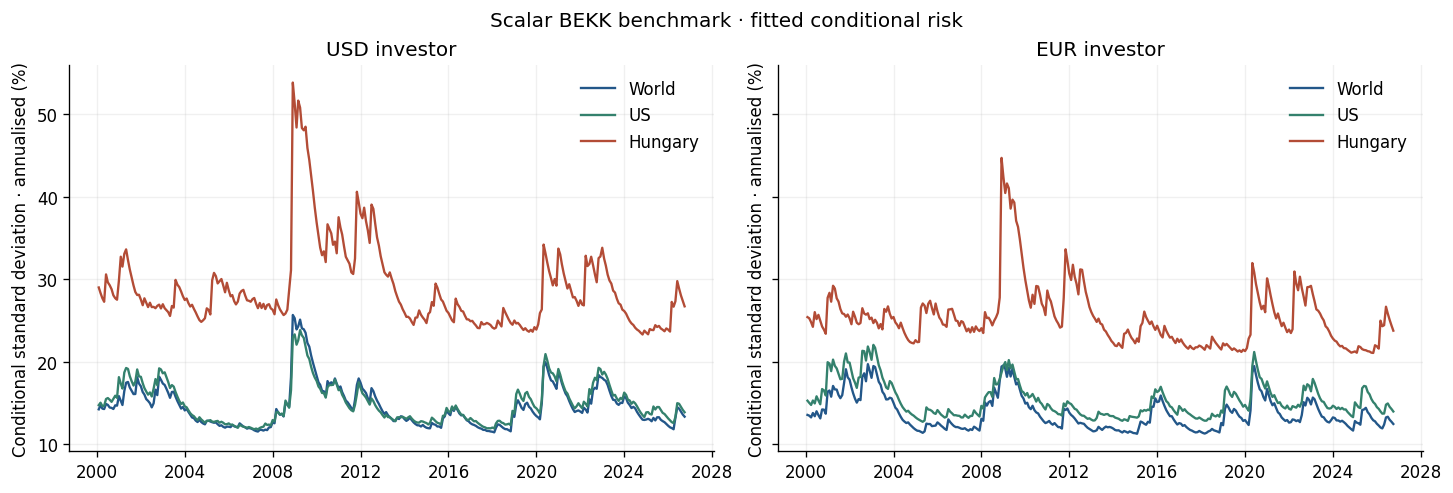

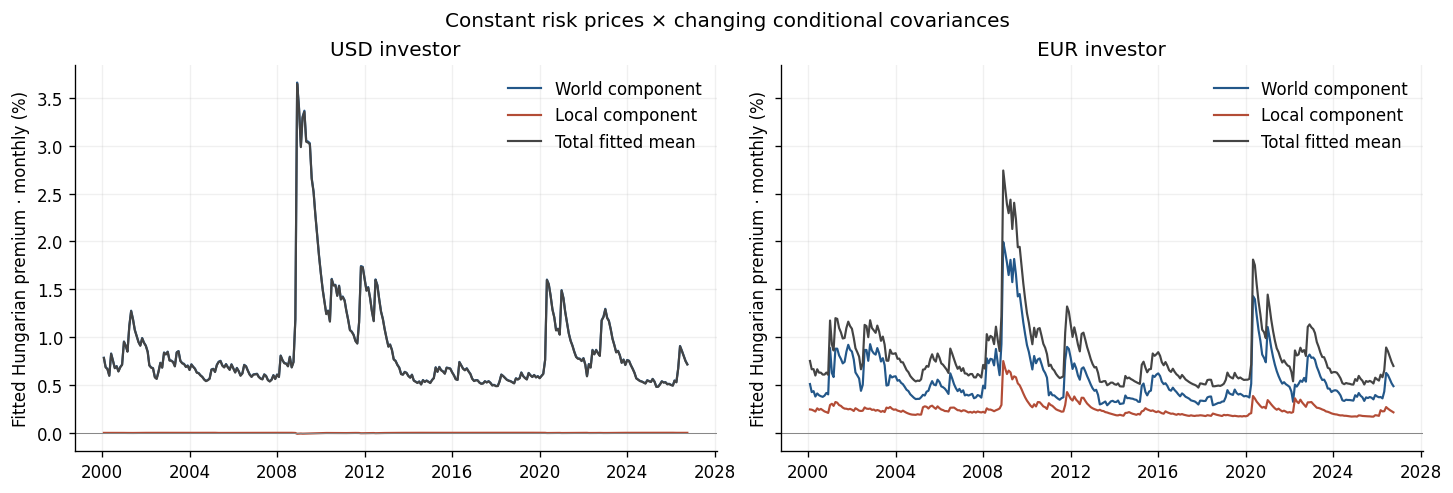

In [9]:
dates = data.index.to_timestamp("M")
colors = {"World": "#235789", "US": "#34816d", "Hungary": "#b34c36"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout="constrained")
for ax, currency in zip(axes, ["USD", "EUR"]):
    filtered = fits[f"{currency}_world_local"]["filter"]
    for j, asset in enumerate(ASSETS):
        ax.plot(dates, np.sqrt(filtered["H"][:, j, j]) * np.sqrt(12), label=asset, color=colors[asset], lw=1.4)
    ax.set(title=f"{currency} investor", ylabel="Conditional standard deviation · annualised (%)")
    ax.legend(frameon=False)
fig.suptitle("Scalar BEKK benchmark · fitted conditional risk")
plt.savefig(OUT / "01_conditional_volatility.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close()

components = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout="constrained")
for ax, currency in zip(axes, ["USD", "EUR"]):
    filtered = fits[f"{currency}_world_local"]["filter"]
    world_component = filtered["prices"][0] * filtered["H"][:, 2, 0]
    local_component = filtered["prices"][2] * filtered["H"][:, 2, 2]
    np.testing.assert_allclose(world_component + local_component, filtered["mu"][:, 2], atol=1e-12, rtol=0)
    components[currency] = pd.DataFrame({"world_premium_pct": world_component,
                                        "local_premium_pct": local_component,
                                        "total_fitted_premium_pct": filtered["mu"][:, 2]}, index=data.index)
    for values, label, color in [(world_component, "World component", colors["World"]),
                                  (local_component, "Local component", colors["Hungary"]),
                                  (filtered["mu"][:, 2], "Total fitted mean", "#444444")]:
        ax.plot(dates, values, label=label, color=color, lw=1.3)
    ax.axhline(0, color="#888888", lw=0.6)
    ax.set(title=f"{currency} investor", ylabel="Fitted Hungarian premium · monthly (%)")
    ax.legend(frameon=False)
fig.suptitle("Constant risk prices × changing conditional covariances")
plt.savefig(OUT / "02_hungary_premium_components.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close()

## 9. Record this first result and decide the next specification

Treat numerical convergence and residual adequacy separately. Positive curvature permits computing
the sandwich; it does not validate the pricing model. In particular, revisit a covariance process that
leaves dependence in squared or cross-product residuals before interpreting its risk-price tests.

In [10]:
summary_rows = []
for currency in ["USD", "EUR"]:
    marginal = residual_table.loc[(currency, "world_local")]
    cross = cross_table.loc[(currency, "world_local")]
    summary_rows.append({"perspective": currency,
        "world_price": price_table.loc[(currency, "world_local", "World"), "estimate"],
        "Hungary_local_price": price_table.loc[(currency, "world_local", "Hungary local"), "estimate"],
        "local_joint_Wald_p": wald_table.loc[currency, "robust_p_value"],
        "mean_diagnostic_flags_5pct": int(marginal["LB_z_p"].lt(0.05).sum()),
        "variance_diagnostic_flags_5pct": int((marginal["LB_z_squared_p"].lt(0.05) | marginal["ARCH_LM_p"].lt(0.05)).sum()),
        "cross_covariance_flags_5pct": int(cross["LB_product_p"].lt(0.05).sum())})
summary = pd.DataFrame(summary_rows).set_index("perspective")
display(summary.round(5))
tables = {"fit_summary.csv": fit_table, "risk_prices.csv": price_table, "local_risk_wald.csv": wald_table,
          "starting_points.csv": starts_table, "residual_diagnostics.csv": residual_table,
          "cross_covariance_diagnostics.csv": cross_table, "summary.csv": summary}
for name, table in tables.items():
    table.to_csv(OUT / name, float_format="%.17g", lineterminator="\n")
for key, fit in fits.items():
    # Retain the full joint parameter covariance, not only price standard errors.
    np.savez(OUT / f"parameters_{key}.npz", theta=fit["theta"], robust_covariance=fit["covariance"],
             H=fit["filter"]["H"], mu=fit["filter"]["mu"], residuals=fit["filter"]["errors"])
for currency, frame in components.items():
    frame.to_csv(OUT / f"hungary_premium_{currency.lower()}.csv", float_format="%.17g", lineterminator="\n")
record = {"model_version": MODEL_VERSION, "source_snapshot": SNAPSHOT,
          "source_dataset_sha256": manifest["exports"]["dataset.csv"],
          "first": str(data.index[0]), "last": str(data.index[-1]), "observations": len(data),
          "return_unit": "monthly log percentage points", "assets": ASSETS,
          "covariance": "scalar BEKK, jointly estimated long-run innovation covariance; H0=Sigma",
          "risk_prices": "constant, unrestricted sign; currency terms omitted",
          "test_lags": TEST_LAGS, "packages": versions, "python": platform.python_version()}
(OUT / "estimation_manifest.json").write_text(json.dumps(record, indent=2, sort_keys=True) + "\n")

issues = []
for currency, row in summary.iterrows():
    if row["variance_diagnostic_flags_5pct"] or row["cross_covariance_flags_5pct"]:
        issues.append(currency)
display(Markdown(
    f"**Completed:** four joint fits on {len(data)} matched months. "
    f"Local-price joint Wald p-values: USD **{wald_table.loc['USD', 'robust_p_value']:.3f}**, "
    f"EUR **{wald_table.loc['EUR', 'robust_p_value']:.3f}**. "
    f"These are conditional on the benchmark specification.\n\n"
    f"**Specification check:** covariance diagnostic flags at a nominal 5% level in "
    f"**{', '.join(issues) or 'neither perspective'}**. "
    f"The next step is to assess a less restrictive covariance process and then add explicit currency "
    f"pricing, retaining the same sample. The earlier EUR/HUF mean-dependence issue must also be "
    f"handled when FX enters the system. Inflation predictors remain deferred.\n\n"
    f"Outputs: `{OUT.relative_to(ROOT)}`. The original snapshot is unchanged."
))

,world_price,Hungary_local_price,local_joint_Wald_p,mean_diagnostic_flags_5pct,variance_diagnostic_flags_5pct,cross_covariance_flags_5pct
perspective,,,,,,
USD,0.03650,-0.00005,0.26866,0,2,1
EUR,0.03976,0.00449,0.34681,0,0,0


**Completed:** four joint fits on 321 matched months. Local-price joint Wald p-values: USD **0.269**, EUR **0.347**. These are conditional on the benchmark specification.

**Specification check:** covariance diagnostic flags at a nominal 5% level in **USD**. The next step is to assess a less restrictive covariance process and then add explicit currency pricing, retaining the same sample. The earlier EUR/HUF mean-dependence issue must also be handled when FX enters the system. Inflation predictors remain deferred.

Outputs: `output/03_pricing_baseline/fixed_2026-11-13/2000-01_2026-09`. The original snapshot is unchanged.